# Feature Importance Analyses for Mislocalization

In [16]:
import polars as pl
import seaborn as sns
from adjustText import adjust_text

controls = {
    "TC": ["EGFP"],
    "NC": ["RHEB", "MAPK9", "PRKACB", "SLIRP"],
    "PC": ["ALK", "ALK_Arg1275Gln", "PTK2B"],
    # "cPC": ["KRAS", "PTK2B", "GHSR", "ABL1", "BRD4", 
    # "OPRM1", "RB1", "ADA", "WT PMP22", "LYN", "TNF", 
    # "CYP2A6", "CSK", "PAK1", "ALDH2", "CHRM3", "KCNQ2", 
    # "ALK T1151M", "PRKCE", "LPAR1", "PLP1"]
}

ctrl_alleles = [k_v for k_v in controls.values()]
ctrl_alleles_flat = [allele for sublist in ctrl_alleles for allele in sublist]
# ctrl_alleles_flat

## Read in feature importance

### Feature importance from two batches

In [2]:
classifier_raw_input_dir = [
    "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/results/2024_01_23_Batch_7/profiles_tcdropped_filtered_var_mad_outlier_featselect",
    "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/results/2024_02_06_Batch_8/profiles_tcdropped_filtered_var_mad_outlier_featselect"
]

feat_dfs = pl.DataFrame()
for batch_dir in classifier_raw_input_dir:
    # Read the data
    feat_df = pl.read_csv(f"{batch_dir}/feat_importance.csv")
    gfp_cols = ["Group1", "Group2"] + [col for col in feat_df.columns if "GFP" in col]
    feat_df = feat_df.select(
        gfp_cols
    ).with_columns(
        pl.lit(batch_dir.split('/')[-2]).alias("batch")
    )
    # print(feat_df)
    feat_dfs = pl.concat([feat_dfs, feat_df], how="diagonal")

### Filter the GFP cols

Filter the cols with all nulls and get the mean feature importance per column

In [3]:
# Filter out columns where all values are null
non_null_cols = [col for col in feat_dfs.columns if not feat_dfs[col].is_null().all()]
feat_df_clean = feat_dfs.select(non_null_cols)

# Group by "Group1" and "Group2" and compute the mean for all columns except "batch"
feat_df_mean = feat_df_clean.group_by(["Group1", "Group2"]).agg( ## , "batch"
    pl.col("*").exclude(["Group1", "Group2", "batch"]).mean()
)
feat_df_mean

Group1,Group2,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_10_03_256,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cytoplasm_Texture_Correlation_GFP_20_03_256,Cells_RadialDistribution_MeanFrac_GFP_5of10,Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,Cells_RadialDistribution_RadialCV_GFP_4of10,Nuclei_Texture_Correlation_GFP_20_00_256,Cells_RadialDistribution_MeanFrac_GFP_9of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_7of10,Nuclei_Granularity_4_GFP,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cytoplasm_Texture_InfoMeas1_GFP_10_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_9of10,Cells_RadialDistribution_FracAtD_GFP_1of10,Nuclei_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_5of10,Cytoplasm_Texture_InverseDifferenceMoment_GFP_20_03_256,Cytoplasm_Location_CenterMassIntensity_Y_GFP,Cells_RadialDistribution_RadialCV_GFP_8of10,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cells_Texture_Correlation_GFP_20_00_256,Cells_RadialDistribution_RadialCV_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_02_256,Cytoplasm_Granularity_4_GFP,Cytoplasm_Intensity_MinIntensity_GFP,Cells_Granularity_5_GFP,Nuclei_Texture_InverseDifferenceMoment_GFP_20_01_256,Nuclei_Texture_Correlation_GFP_10_00_256,Cytoplasm_RadialDistribution_MeanFrac_GFP_2of10,Cytoplasm_RadialDistribution_RadialCV_GFP_1of10,Cells_RadialDistribution_MeanFrac_GFP_2of10,…,Cells_Texture_InfoMeas2_GFP_10_03_256,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Texture_InfoMeas1_GFP_10_02_256,Nuclei_RadialDistribution_FracAtD_GFP_2of10,Cells_Texture_InfoMeas1_GFP_5_01_256,Cytoplasm_RadialDistribution_RadialCV_GFP_4of10,Cells_RadialDistribution_RadialCV_GFP_5of10,Nuclei_RadialDistribution_FracAtD_GFP_4of10,Cytoplasm_Texture_InfoMeas1_GFP_5_00_256,Cells_RadialDistribution_FracAtD_GFP_2of10,Nuclei_RadialDistribution_MeanFrac_GFP_4of10,Cells_Granularity_6_GFP,Cytoplasm_RadialDistribution_MeanFrac_GFP_4of10,Cells_Texture_Correlation_GFP_5_02_256,Cytoplasm_Intensity_MassDisplacement_GFP,Cells_Texture_InverseDifferenceMoment_GFP_10_01_256,Nuclei_Texture_Correlation_GFP_5_02_256,Nuclei_Texture_DifferenceEntropy_GFP_5_00_256,Nuclei_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_InfoMeas1_GFP_5_02_256,Nuclei_RadialDistribution_FracAtD_GFP_6of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_1of10,Nuclei_Texture_Correlation_GFP_5_00_256,Cytoplasm_Texture_DifferenceVariance_GFP_10_01_256,Cytoplasm_Texture_AngularSecondMoment_GFP_5_00_256,Cells_Texture_InfoMeas1_GFP_5_00_256,Nuclei_RadialDistribution_MeanFrac_GFP_5of10,Nuclei_RadialDistribution_FracAtD_GFP_5of10,Cells_RadialDistribution_MeanFrac_GFP_1of10,Nuclei_RadialDistribution_FracAtD_GFP_3of10,Nuclei_Texture_InverseDifferenceMoment_GFP_10_00_256,Cytoplasm_RadialDistribution_FracAtD_GFP_3of10,Cytoplasm_Texture_Correlation_GFP_5_00_256,Cells_Intensity_MinIntensity_GFP,Cytoplasm_RadialDistribution_FracAtD_GFP_7of10,Cytoplasm_Texture_InfoMeas2_GFP_10_03_256,Nuclei_Granularity_5_GFP
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GYPA""","""GYPA_GYPA_Arg5…",0.000166,0.002942,0.005524,0.001395,0.004387,0.0,0.0,0.004189,0.004084,0.004681,0.0,0.002429,0.002994,0.002321,0.0,0.0,0.00083,0.001085,0.003182,0.000558,0.001479,0.002611,0.002224,0.006674,0.000654,0.003237,0.0,0.0,0.002736,0.003938,0.001584,0.0,0.81697,0.000581,0.002293,…,0.0,0.0,0.0,0.00128,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""ACSF3""","""ACSF3_ACSF3_Se…",0.001187,0.001986,0.0106,0.003964,0.014394,0.004592,0.003668,0.0

In [4]:
# Filter out columns where any values are null
meta_cols = [col for col in feat_df_mean.columns if "GFP" not in col]
gfp_cols = [col for col in feat_df_mean.columns if "GFP" in col]
non_null_cols = [col for col in gfp_cols if not feat_df_mean[col].is_nan().any() and not feat_df_mean[col].is_null().any()]

feat_df_mean = feat_df_mean.select(meta_cols+non_null_cols).with_columns(
    pl.when(pl.col("Group1").is_in(ctrl_alleles_flat) | pl.col("Group2").is_in(ctrl_alleles_flat))
    .then(pl.lit("Control"))
    .otherwise(pl.lit("Allele"))
    .alias("Variant_Type")
)
feat_df_mean

Group1,Group2,Cytoplasm_Texture_Correlation_GFP_10_02_256,Cytoplasm_Texture_Correlation_GFP_10_03_256,Cells_RadialDistribution_MeanFrac_GFP_10of10,Cytoplasm_RadialDistribution_RadialCV_GFP_3of10,Cells_RadialDistribution_MeanFrac_GFP_6of10,Cytoplasm_Texture_Correlation_GFP_10_01_256,Cytoplasm_Texture_Correlation_GFP_20_03_256,Cells_RadialDistribution_MeanFrac_GFP_5of10,Cytoplasm_RadialDistribution_FracAtD_GFP_9of10,Cells_RadialDistribution_RadialCV_GFP_4of10,Nuclei_Texture_Correlation_GFP_20_00_256,Cells_RadialDistribution_MeanFrac_GFP_9of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_7of10,Nuclei_Granularity_4_GFP,Cytoplasm_Texture_Correlation_GFP_10_00_256,Cytoplasm_Texture_InfoMeas1_GFP_10_00_256,Cytoplasm_RadialDistribution_RadialCV_GFP_9of10,Cytoplasm_RadialDistribution_RadialCV_GFP_5of10,Cells_RadialDistribution_RadialCV_GFP_8of10,Nuclei_RadialDistribution_FracAtD_GFP_10of10,Cells_Texture_Correlation_GFP_20_00_256,Cells_RadialDistribution_RadialCV_GFP_10of10,Cytoplasm_Texture_Correlation_GFP_20_02_256,Cytoplasm_Granularity_4_GFP,Cells_Granularity_5_GFP,Nuclei_Texture_InverseDifferenceMoment_GFP_20_01_256,Cytoplasm_Granularity_1_GFP,Cells_RadialDistribution_MeanFrac_GFP_7of10,Cells_RadialDistribution_RadialCV_GFP_6of10,Cells_Texture_Correlation_GFP_20_02_256,Cytoplasm_RadialDistribution_FracAtD_GFP_8of10,Cells_RadialDistribution_MeanFrac_GFP_3of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_6of10,Cells_RadialDistribution_FracAtD_GFP_5of10,Nuclei_Granularity_3_GFP,…,Nuclei_Texture_Correlation_GFP_20_02_256,Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,Nuclei_RadialDistribution_RadialCV_GFP_4of10,Nuclei_RadialDistribution_FracAtD_GFP_1of10,Nuclei_RadialDistribution_MeanFrac_GFP_9of10,Nuclei_Texture_SumAverage_GFP_20_00_256,Cells_Granularity_4_GFP,Cells_RadialDistribution_RadialCV_GFP_7of10,Cytoplasm_Granularity_3_GFP,Nuclei_RadialDistribution_RadialCV_GFP_3of10,Nuclei_RadialDistribution_RadialCV_GFP_1of10,Cells_RadialDistribution_FracAtD_GFP_8of10,Nuclei_RadialDistribution_MeanFrac_GFP_1of10,Cytoplasm_Texture_InfoMeas1_GFP_5_01_256,Cytoplasm_Texture_Correlation_GFP_20_00_256,Cells_Texture_InfoMeas1_GFP_10_00_256,Nuclei_RadialDistribution_FracAtD_GFP_7of10,Cells_RadialDistribution_FracAtD_GFP_4of10,Cells_RadialDistribution_MeanFrac_GFP_8of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_9of10,Cytoplasm_RadialDistribution_FracAtD_GFP_10of10,Cells_RadialDistribution_RadialCV_GFP_3of10,Cytoplasm_RadialDistribution_MeanFrac_GFP_10of10,Cells_RadialDistribution_FracAtD_GFP_3of10,Nuclei_Intensity_MassDisplacement_GFP,Cytoplasm_Texture_InfoMeas1_GFP_5_03_256,Nuclei_RadialDistribution_FracAtD_GFP_9of10,Cells_Texture_InfoMeas1_GFP_10_02_256,Nuclei_Texture_Correlation_GFP_20_01_256,Nuclei_Texture_DifferenceVariance_GFP_10_01_256,Cells_RadialDistribution_MeanFrac_GFP_4of10,Nuclei_RadialDistribution_RadialCV_GFP_10of10,Nuclei_Texture_Correlation_GFP_20_03_256,Cytoplasm_Texture_InfoMeas1_GFP_10_02_256,Nuclei_RadialDistribution_FracAtD_GFP_2of10,Cells_Texture_InfoMeas1_GFP_5_01_256,Variant_Type
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""GYPA""","""GYPA_GYPA_Arg5…",0.000166,0.002942,0.005524,0.001395,0.004387,0.0,0.0,0.004189,0.004084,0.004681,0.0,0.002429,0.002994,0.002321,0.0,0.0,0.00083,0.000558,0.002224,0.006674,0.000654,0.003237,0.0,0.0,0.003938,0.001584,0.004559,0.001534,0.00152,0.001404,0.002909,0.001734,0.001164,0.002699,0.001152,…,0.000356,0.000097,0.002237,0.00578,0.001056,0.0,0.000309,0.001832,0.004077,0.000678,0.005503,0.0024,0.001947,0.0,0.000542,0.0,0.013909,0.0,0.0,0.0,0.002003,0.001452,0.001017,0.002476,0.001878,0.0,0.001211,0.0,0.0,0.0,0.0,0.009606,0.0,0.0,0.00128,0.0,"""Allele"""
"""ACSF3""","""ACSF3_ACSF3_Se…",0.001187,0.001986,0.0106,0.003964,0.014394,0.004592,0.003668,0.00

## Read in the results

In [5]:
trn_imbalance_thresh = 3

# Paths
metrics_dir = "../1_snakemake_pipeline/2025_varchamp_snakemake/snakemake_pipeline/outputs/analyses/{}/profiles_tcdropped_filtered_var_mad_outlier_featselect"
batches = ["2024_01_23_Batch_7", "2024_02_06_Batch_8"]

metrics_df, metrics_wtvar = pl.DataFrame(), pl.DataFrame()
for batch in batches:
    met_dir = metrics_dir.format(batch)
    metrics_df_batch = pl.read_csv(f"{met_dir}/metrics.csv")
    metrics_wtvar_batch = pl.read_csv(f"{met_dir}/metrics_summary.csv")

    metrics_df = pl.concat([metrics_df, metrics_df_batch])
    metrics_wtvar = pl.concat([metrics_wtvar, metrics_wtvar_batch])

## get the localization metrics
local_wtvar = metrics_wtvar.filter(pl.col("Classifier_type") == "localization")
## get the alleles and their reference genes
local_wtvar = local_wtvar.with_columns(
    pl.when(pl.col("AUROC_mean") > pl.col("AUROC_thresh"))
    .then(1)
    .otherwise(0)
    .alias("mislocalized")
).unique()

local_wtvar

Classifier_type,allele_0,Allele_set,Batch,AUROC_thresh,AUROC_mean,trainsize_0_mean,testsize_0_mean,trainsize_1_mean,testsize_1_mean,Training_imbalance_mean,mislocalized
str,str,str,str,f64,f64,f64,f64,f64,f64,f64,i32
"""localization""","""AGXT_Gly82Arg""","""A1P1""","""B7""",0.71418,0.824847,1398.75,466.25,1590.75,530.25,1.137224,1
"""localization""","""PRKAR1A_Arg74H…","""A1P3""","""B7""",0.71418,0.560387,1245.75,415.25,1398.75,466.25,1.12114,0
"""localization""","""DES_His441Leu""","""A1P1""","""B8""",0.861392,0.713322,301.5,100.5,318.75,106.25,1.162053,0
"""localization""","""RNF135_Arg286H…","""A1P3""","""B7""",0.71418,0.992784,895.5,298.5,532.5,177.5,1.682346,1
"""localization""","""DOLK_Tyr441Ser…","""A1P1""","""B7""",0.71418,0.500317,782.25,260.75,729.75,243.25,1.074122,0
"""localization""","""AGXT_Met49Leu""","""A1P1""","""B7""",0.71418,0.578174,1010.25,336.75,1590.75,530.25,1.5726,0
"""localization""","""DES_Gly20Arg""","""A1P1""","""B8""",0.861392,0.610196,198.0,66.0,318.75,106.25,1.61058,0
"""localization""","""STAR_Arg182His…","""A1P4""","""B8""",0.861392,0.540496,155.25,51.75,159.0,53.0,1.023954,0
"""localization""","""KRT86_Glu413Ly…","""A1P2""","""B8""",0.861392,0.839244,174.0,58.0,329.25,109.75,1.919261,0


In [31]:
misloc_binary = (
    local_wtvar.pivot(
        index=["allele_0", "Allele_set"], ## , "AUROC_mean"
        columns="Batch",
        values="mislocalized",
    )
    .with_columns(
        ((pl.col("B7") == 1) & (pl.col("B8") == 1)).alias(
            "mislocalized_both_batches"
        )
    )
    .rename({"B7": "mislocalized_batch7", "B8": "mislocalized_batch8"})
)

misloc_binary #.filter(pl.col("mislocalized_both_batches"))["allele_0"]

allele_0,Allele_set,mislocalized_batch7,mislocalized_batch8,mislocalized_both_batches
str,str,i32,i32,bool
"""AGXT_Gly82Arg""","""A1P1""",1,0,false
"""PRKAR1A_Arg74H…","""A1P3""",0,0,false
"""DES_His441Leu""","""A1P1""",0,0,false
"""RNF135_Arg286H…","""A1P3""",1,null,null
"""DOLK_Tyr441Ser…","""A1P1""",0,0,false
"""AGXT_Met49Leu""","""A1P1""",0,0,false
"""DES_Gly20Arg""","""A1P1""",0,0,false
"""STAR_Arg182His…","""A1P4""",0,0,false
"""KRT86_Glu413Ly…","""A1P2""",1,0,false


## DR on Feature Importance

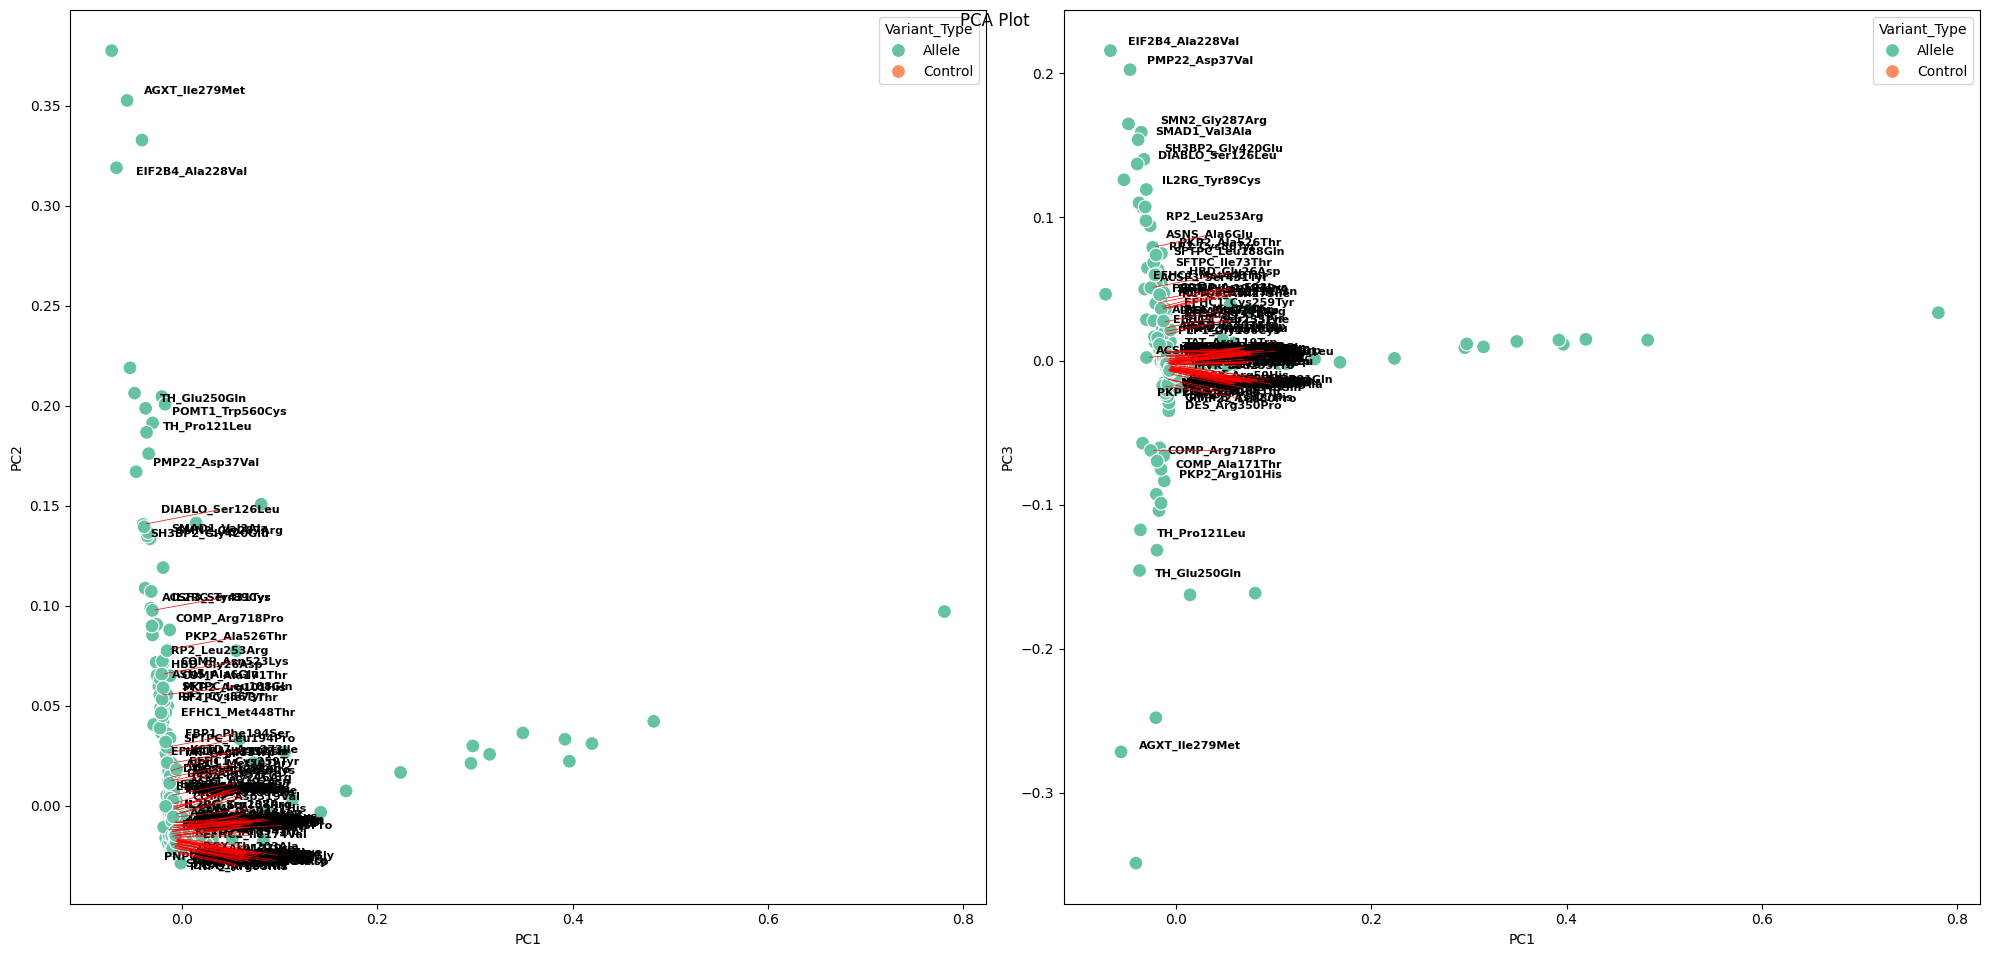

In [ ]:
from sklearn.decomposition import PCA
import umap
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd

# Standardize the features before PCA
scaler = StandardScaler()
numeric_cols = feat_df_mean.select(pl.col("*").exclude(["Group1", "Group2", "Variant_Type"])).to_pandas()
# numeric_cols = pd.DataFrame(scaler.fit_transform(numeric_cols), columns=numeric_cols.columns)
variant_type = feat_df_mean["Variant_Type"].to_pandas()
group2_labels = feat_df_mean["Group2"].to_pandas().apply(lambda x: '_'.join(x.split("_")[1:]) if "_" in x else x)

# Perform PCA
pca = PCA(n_components=10)
pca_result = pca.fit_transform(numeric_cols)

# Plot PCA
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=variant_type, palette="Set2", s=100, ax=ax[0])
texts = []
for i, label in enumerate(group2_labels):
    if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
        texts.append(ax[0].text(pca_result[i, 0], pca_result[i, 1], label, 
                     fontsize=8, fontweight='bold', color='black'))
# print(texts)
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[0]) ## 
ax[0].set_xlabel("PC1")
ax[0].set_ylabel("PC2")

sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 2], hue=variant_type, palette="Set2", s=100, ax=ax[1])
ax[1].set_xlabel("PC1")
ax[1].set_ylabel("PC3")
texts = []
for i, label in enumerate(group2_labels):
    if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
        texts.append(ax[1].text(pca_result[i, 0], pca_result[i, 2], label, 
                     fontsize=8, fontweight='bold', color='black'))
ax[1].legend(title="Variant_Type")
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax[1])

fig.suptitle("PCA Plot", y=0.95)
plt.tight_layout()

In [52]:
# Get PCA loading scores
pca_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=numeric_cols.columns
)
pca_loadings.sort_values(by="PC1", ascending=False, inplace=True)
pca_loadings

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
Cells_RadialDistribution_RadialCV_GFP_1of10,0.149546,-0.045842,-0.068198,-0.005022,0.005327,-0.015332,0.019011,-0.004923,-0.025483,-0.042136
Cells_RadialDistribution_FracAtD_GFP_9of10,0.149312,-0.003923,0.040019,-0.069427,-0.108335,-0.037244,0.005275,-0.024815,-0.047080,0.001373
Cells_RadialDistribution_FracAtD_GFP_8of10,0.147179,-0.025580,0.058688,-0.070340,-0.069508,0.010938,-0.087908,-0.103966,-0.010644,-0.020505
Nuclei_Texture_Correlation_GFP_20_03_256,0.145849,0.124314,-0.033257,-0.102617,0.048188,0.002527,0.011689,-0.063317,-0.038111,0.025398
Nuclei_Texture_Correlation_GFP_20_02_256,0.145768,0.082447,-0.055333,-0.064138,0.018591,0.004379,0.014377,-0.044065,-0.035135,0.015852
...,...,...,...,...,...,...,...,...,...,...
Cells_Texture_InfoMeas1_GFP_5_03_256,-0.039135,0.083104,-0.131282,-0.100406,-0.112212,-0.185732,-0.094674,0.026729,0.373820,0.242255
Cells_RadialDistribution_RadialCV_GFP_10of10,-0.060613,0.058453,0.015980,-0.080791,-0.111281,0.307749,0.034846,0.077867,-0.046147,0.056534
Cytoplasm_Granularity_1_GFP,-0.064005,0.021078,-0.129139,-0.031175,-0.068889,0.158428,-0.102055,0.155833,0.032952,0.079567
Cytoplasm_RadialDistribution_RadialCV_GFP_10of10,-0.067020,0.035088,-0.023901,-0.070067,-0.149324,0.359249,-0.017400,0.101311,-0.164765,0.041937


In [55]:
# Perform UMAP
umap_model = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
umap_result = umap_model.fit_transform(numeric_cols)

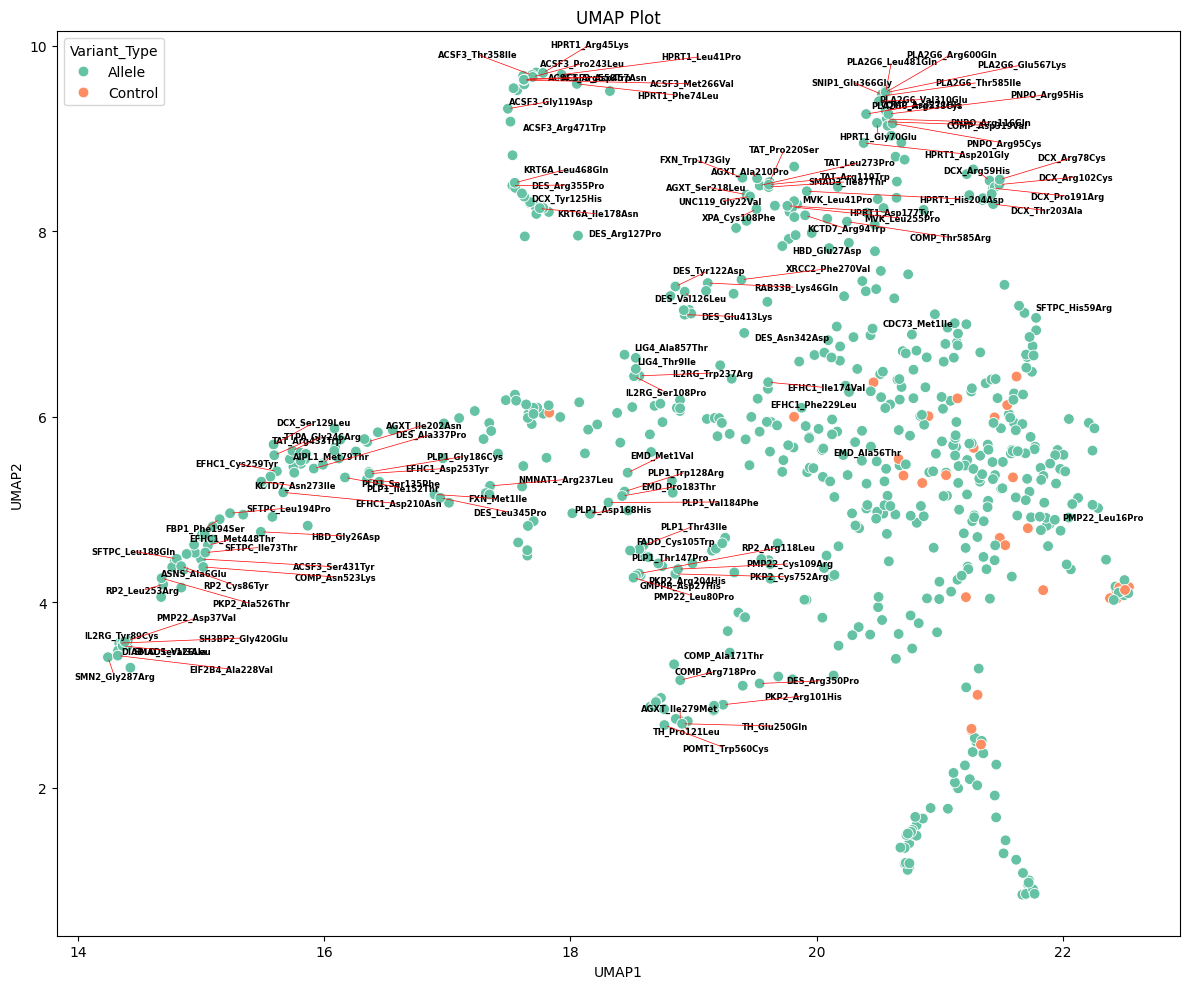

In [59]:
# Plot UMAP
fig, ax = plt.subplots(1, 1, figsize=(12, 10))
sns.scatterplot(x=umap_result[:, 0], y=umap_result[:, 1], hue=variant_type, palette="Set2", s=60, ax=ax)
texts = []
for i, label in enumerate(group2_labels):
    if label in misloc_binary.filter(pl.col("mislocalized_both_batches"))["allele_0"]:
        texts.append(ax.text(umap_result[i, 0], umap_result[i, 1], label, 
                     fontsize=6, fontweight='bold', color='black'))
adjust_text(texts, expand_points=(2, 2), arrowprops=dict(arrowstyle='-', color='red', lw=0.5), ax=ax) ## 
ax.set_title("UMAP Plot")
ax.set_xlabel("UMAP1")
ax.set_ylabel("UMAP2")
ax.legend(title="Variant_Type")
plt.tight_layout()
plt.show()